# Klasifikasi Naive Bayes — PBL Harga Properti

Bagian dari perbandingan 3 metode klasifikasi: **kNN, SVM, Naive Bayes**.
Data: `data_preprocessed.csv` (hasil `Preprocessing.ipynb`, preprocessing identik untuk semua metode).

Target: `kelas_harga` (Murah / Sedang / Mahal) — 15.000 data, 5 fitur ter-scaling.

## 1. Load Data & Split (80:20, stratified, random_state=42)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

df = pd.read_csv('data_preprocessed.csv')
X = df.drop(columns=['kelas_harga'])
y = df['kelas_harga']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Train: {X_train.shape[0]} | Test: {X_test.shape[0]}')
print(df['kelas_harga'].value_counts())

Train: 12000 | Test: 3000
kelas_harga
Sedang    5020
Mahal     4999
Murah     4981
Name: count, dtype: int64


## 2. Perbandingan Varian Naive Bayes

Varian NB dibedakan oleh **asumsi distribusi fitur**:

- **GaussianNB** — fitur kontinu berdistribusi normal (cocok untuk data ter-scaling seperti ini)
- **BernoulliNB** — fitur biner (fitur di-binarisasi dulu dengan threshold)
- **MultinomialNB** — *tidak dapat dipakai* di sini karena mewajibkan fitur non-negatif,
  sedangkan hasil StandardScaler mengandung nilai negatif (dibahas di analisis)

In [2]:
hasil_nb = []

# GaussianNB — langsung pada fitur kontinu
gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred_g = gnb.predict(X_test)
hasil_nb.append({
    'Varian': 'GaussianNB',
    'Akurasi Train': gnb.score(X_train, y_train),
    'Akurasi': accuracy_score(y_test, y_pred_g),
    'Precision (macro)': precision_score(y_test, y_pred_g, average='macro'),
    'Recall (macro)': recall_score(y_test, y_pred_g, average='macro'),
    'F1 (macro)': f1_score(y_test, y_pred_g, average='macro'),
})
print(f"GaussianNB -> train: {hasil_nb[-1]['Akurasi Train']:.4f} | test: {hasil_nb[-1]['Akurasi']:.4f}")

# BernoulliNB — fitur di-binarisasi (di atas median train -> 1, selainnya 0)
median_train = X_train.median()
X_train_bin = (X_train > median_train).astype(int)
X_test_bin = (X_test > median_train).astype(int)

bnb = BernoulliNB()
bnb.fit(X_train_bin, y_train)
y_pred_b = bnb.predict(X_test_bin)
hasil_nb.append({
    'Varian': 'BernoulliNB (biner)',
    'Akurasi Train': bnb.score(X_train_bin, y_train),
    'Akurasi': accuracy_score(y_test, y_pred_b),
    'Precision (macro)': precision_score(y_test, y_pred_b, average='macro'),
    'Recall (macro)': recall_score(y_test, y_pred_b, average='macro'),
    'F1 (macro)': f1_score(y_test, y_pred_b, average='macro'),
})
print(f"BernoulliNB -> train: {hasil_nb[-1]['Akurasi Train']:.4f} | test: {hasil_nb[-1]['Akurasi']:.4f}")

tabel_nb = pd.DataFrame(hasil_nb).round(4)
tabel_nb

GaussianNB -> train: 0.5830 | test: 0.5893
BernoulliNB -> train: 0.6394 | test: 0.6363


,Varian,Akurasi Train,Akurasi,Precision (macro),Recall (macro),F1 (macro)
0,GaussianNB,0.5830,0.5893,0.6179,0.590,0.5801
1,BernoulliNB (biner),0.6394,0.6363,0.6191,0.637,0.6175


## 3. Model Final Naive Bayes (varian terbaik)

In [3]:
if hasil_nb[0]['F1 (macro)'] >= hasil_nb[1]['F1 (macro)']:
    nb_final, y_pred_final, nama_final = gnb, y_pred_g, 'GaussianNB'
else:
    nb_final, y_pred_final, nama_final = bnb, y_pred_b, 'BernoulliNB'

print(f'Varian terbaik: {nama_final}')
print(f"\nAkurasi  : {accuracy_score(y_test, y_pred_final):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_final, average='macro'):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_final, average='macro'):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred_final, average='macro'):.4f}")
print()
print(classification_report(y_test, y_pred_final))

Varian terbaik: BernoulliNB

Akurasi  : 0.6363


Precision: 0.6191
Recall   : 0.6370
F1-score : 0.6175

              precision    recall  f1-score   support

       Mahal       0.71      0.73      0.72      1000
       Murah       0.65      0.85      0.73       996
      Sedang       0.50      0.33      0.40      1004

    accuracy                           0.64      3000
   macro avg       0.62      0.64      0.62      3000
weighted avg       0.62      0.64      0.62      3000



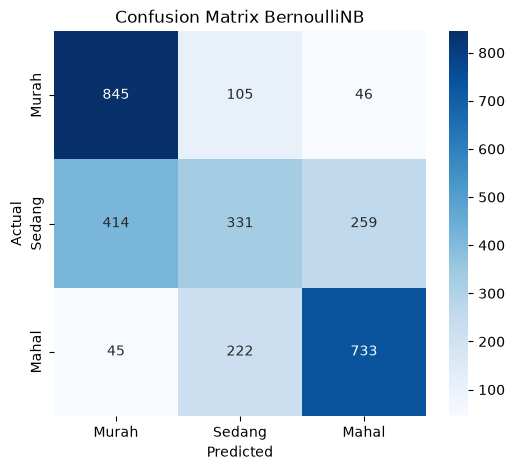

In [4]:
cm = confusion_matrix(y_test, y_pred_final, labels=['Murah', 'Sedang', 'Mahal'])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Murah', 'Sedang', 'Mahal'],
            yticklabels=['Murah', 'Sedang', 'Mahal'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix {nama_final}')
plt.show()

## 4. Simpan Hasil (untuk notebook Perbandingan)

In [5]:
hasil_nb_final = {
    'Metode': 'Naive Bayes',
    'Konfigurasi': nama_final,
    'Akurasi': accuracy_score(y_test, y_pred_final),
    'Precision': precision_score(y_test, y_pred_final, average='macro'),
    'Recall': recall_score(y_test, y_pred_final, average='macro'),
    'F1': f1_score(y_test, y_pred_final, average='macro'),
}
pd.DataFrame([hasil_nb_final]).to_csv('hasil_nb.csv', index=False)
print('Tersimpan: hasil_nb.csv')
pd.DataFrame([hasil_nb_final]).round(4)

Tersimpan: hasil_nb.csv


,Metode,Konfigurasi,Akurasi,Precision,Recall,F1
0,Naive Bayes,BernoulliNB,0.6363,0.6191,0.637,0.6175


## 5. Analisis Naive Bayes

**(a) Perbandingan varian:**

| Varian | Akurasi Train | Akurasi Test | F1 (macro) |
|---|---|---|---|
| GaussianNB | 0.5830 | 0.5893 | 0.5801 |
| **BernoulliNB (biner)** | **0.6394** | **0.6363** | **0.6175** |

**(b) Pembahasan:**

- **BernoulliNB mengungguli GaussianNB** (0.6363 vs 0.5893). Ini menarik karena fitur kita kontinu, yang secara teori cocok untuk Gaussian. Namun GaussianNB mengasumsikan tiap fitur berdistribusi **normal per kelas** — fitur properti seperti luas dan jumlah kamar cenderung **miring (skewed)** dan tidak normal, sehingga asumsi Gaussian meleset. BernoulliNB justru lebih robust: dengan binarisasi di median, fitur disederhanakan menjadi "di atas/di bawah rata-rata" — informasi yang ternyata sudah cukup membedakan Murah/Mahal.
- **MultinomialNB tidak dapat digunakan** karena mewajibkan fitur non-negatif (dirancang untuk data hitungan), sedangkan hasil StandardScaler mengandung nilai negatif. Ini alasan metodologis mengapa hanya dua varian yang diuji — penting dicatat di laporan.
- **Performa per kelas** (BernoulliNB): Murah recall tertinggi (0.85 — jarang terlewat), Mahal F1=0.72, dan seperti metode lain **Sedang paling sulit** (F1=0.40, recall 0.33) karena berbatasan dengan kedua kelas.
- NB adalah metode **tercepat** dari ketiga metode (pelatihan hampir instan) — keunggulan praktis meskipun akurasinya paling rendah.

**(c) Kesimpulan:** model final **BernoulliNB** dengan akurasi test **0.6363** — di bawah kNN dan SVM, konsekuensi dari asumsi independensi antar fitur yang kuat, padahal fitur properti jelas saling berkorelasi (luas ↔ jumlah kamar ↔ harga).